# Problem Set 4 — Solutions

**OE 754/854 — Ocean Waves & Tides**

Topics: shoaling, refraction, breaking, seiches.

Released after the PS4 submission deadline. Homework is graded for submission only, so nothing here is a rubric. Compare it with what you wrote. Whatever differs is what to review before the exams. Each derivation below is followed by a short numerical check. Run the notebook top to bottom. Keep `solutions/` and `notebooks/` as sibling directories so the shared figure style imports.

Companion notebooks:

- `week08_shoaling_refraction.ipynb`: the `inshore()` recipe and the ray tracer (Problems 1 and 2).
- `week09_diffraction_reflection_breaking.ipynb`: the Iribarren diagram and the Merian and Helmholtz calculations (Problems 3 and 4).


In [1]:
import sys
sys.path.insert(0, ".")

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
import figure_style as fs

g = 9.81
rho = 1025.0    # seawater


def newton_k(omega, h, tol=1e-14):
    # Newton iteration on f(k) = g k tanh(kh) - omega^2
    k = omega**2/g
    for _ in range(200):
        t = np.tanh(k*h)
        dk = (g*k*t - omega**2)/(g*t + g*k*h/np.cosh(k*h)**2)
        k -= dk
        if abs(dk) < tol:
            break
    return k

## Problem 1. Shoaling and refraction.

Offshore wave: $H_0 = 3$ m, $T = 10$ s, $\theta_0 = 35^\circ$ from shore-normal. Depth contours are straight and parallel. Deep-water reference values: $L_0 = gT^2/2\pi = 156.1$ m, $C_0 = 15.61$ m/s, $C_{g0} = C_0/2 = 7.81$ m/s. (At $h = 200$ m, $kh = 8.05$ and $\tanh kh = 1$ to seven digits, so the first table row *is* deep water.)

**Setup.**

*Dispersion* gives the local wavelength and speeds at each depth (Newton solve, as in PS2 Problem 7):

$$
\omega^2 = gk\tanh kh, \qquad C = \frac{\omega}{k}, \qquad C_g = nC,\quad n = \frac{1}{2}\left[1 + \frac{2kh}{\sinh 2kh}\right].
$$

*Snell's law.* With straight contours, the alongshore wavenumber component $k\sin\theta$ is conserved. (The wave field is uniform alongshore, so the alongshore phase gradient does not change.) Since $\omega$ is fixed, $k\sin\theta = k_0\sin\theta_0$ is equivalent to

$$
\frac{\sin\theta}{C} = \frac{\sin\theta_0}{C_0}
\qquad\Longrightarrow\qquad
\theta = \arcsin\!\left(\sin\theta_0\,\frac{C}{C_0}\right).
$$

As $C$ drops in shallowing water, $\theta$ drops: crests swing parallel to shore.

*Energy flux between rays.* For steady, unbroken waves the flux between two adjacent rays is conserved ($b$ is the ray spacing): $E\,C_g\,b = E_0\,C_{g0}\,b_0$. Geometry of straight contours gives $b/b_0 = \cos\theta/\cos\theta_0$. With $E \propto H^2$,

$$
H^2 C_g\cos\theta = H_0^2\,C_{g0}\cos\theta_0
\qquad\Longrightarrow\qquad
H = H_0\,\underbrace{\sqrt{\frac{C_{g0}}{C_g}}}_{K_s}\,\underbrace{\sqrt{\frac{\cos\theta_0}{\cos\theta}}}_{K_r}.
$$

**Results** (computed and tabulated in the code cell below):

| $h$ (m) | $L$ (m) | $C$ (m/s) | $C_g$ (m/s) | $\theta$ (deg) | $K_s$ | $K_r$ | $H$ (m) |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 200 | 156.1 | 15.61 | 7.81 | 35.0 | 1.000 | 1.000 | 3.00 |
| 50 | 151.3 | 15.13 | 8.55 | 33.8 | 0.955 | 0.993 | 2.85 |
| 20 | 121.2 | 12.12 | 9.27 | 26.4 | 0.917 | 0.957 | 2.63 |
| 10 | 92.4 | 9.24 | 8.07 | 19.8 | 0.984 | 0.933 | 2.75 |
| 5 | 67.7 | 6.77 | 6.33 | 14.4 | 1.111 | 0.920 | 3.06 |
| 2 | 43.7 | 4.37 | 4.25 | 9.2 | 1.355 | 0.911 | 3.70 |

**Dip in wave height.** $H(h)$ *falls* from 3.00 m to a minimum of about 2.63 m near $h \approx 20$ m, then rises steeply. Two effects compete. $K_s = \sqrt{C_{g0}/C_g}$ first dips below 1, since $C_g$ *increases* through intermediate depths (PS3 Problem 4c) before dropping in shallow water. Meanwhile $K_r < 1$ monotonically as refraction spreads the rays apart ($\cos\theta$ grows). Refraction and the $C_g$ maximum win offshore. Shallow-water shoaling ($K_s \propto h^{-1/4}$ as $C_g \to \sqrt{gh}$) wins at the coast. Obliquely incident swell shows this dip, then rise.

**Breaking depth.** The McCowan criterion $H/h = \kappa = 0.78$ is first reached (root-finding on the table's formula chain) at

$$
h_b \approx 4.1\ \mathrm{m}, \qquad H_b \approx 3.2\ \mathrm{m}.
$$

Compare the Week 9 closed form. It assumes the shallow-water asymptotes $C_g \to \sqrt{gh}$, $\cos\theta \to 1$ at breaking. From $H^2 C_g\cos\theta = H_0^2 C_{g0}\cos\theta_0$ with $H = \kappa h_b$ and $C_{g0} = C_0/2$:

$$
\kappa^2 h_b^2\sqrt{g h_b} = \frac{H_0^2 C_0\cos\theta_0}{2}
\qquad\Longrightarrow\qquad
h_b = \frac{1}{g^{1/5}\kappa^{4/5}}\left[\frac{H_0^2 C_0\cos\theta_0}{2}\right]^{2/5} \approx 3.9\ \mathrm{m},
$$

within about 5% of the full dispersion-relation iteration. The difference comes from the shallow-water approximation: $kh \approx 0.5$ at breaking, so $C_g$ is still a few percent below $\sqrt{gh}$, and $\cos\theta = 0.97 \neq 1$.

In [2]:
from scipy.optimize import brentq

H0, T, theta0 = 3.0, 10.0, np.deg2rad(35.0)
omega = 2 * np.pi / T
C0 = g * T / (2 * np.pi)
Cg0 = C0 / 2


def local_wave(h):
    # Return (L, C, Cg, theta, Ks, Kr, H) at depth h for the Problem 1 offshore wave
    k = newton_k(omega, h)
    kh = k * h
    C = omega / k
    n = 0.5 * (1 + 2 * kh / np.sinh(2 * kh))
    Cg = n * C
    theta = np.arcsin(np.sin(theta0) * C / C0)
    Ks = np.sqrt(Cg0 / Cg)
    Kr = np.sqrt(np.cos(theta0) / np.cos(theta))
    return 2 * np.pi / k, C, Cg, theta, Ks, Kr, H0 * Ks * Kr


print(f"L0 = {g*T**2/(2*np.pi):.1f} m,  C0 = {C0:.2f} m/s,  Cg0 = {Cg0:.2f} m/s\n")
print(f"{'h (m)':>6} {'L (m)':>7} {'C':>6} {'Cg':>6} {'theta':>7} {'Ks':>6} {'Kr':>6} {'H (m)':>6} {'H/h':>6}")
for h in [200, 50, 20, 10, 5, 2]:
    L, C, Cg, th, Ks, Kr, Hh = local_wave(h)
    print(f"{h:6.0f} {L:7.1f} {C:6.2f} {Cg:6.2f} {np.rad2deg(th):7.1f} {Ks:6.3f} {Kr:6.3f} {Hh:6.2f} {Hh/h:6.3f}")

# Breaking: McCowan H/h = 0.78, direct iteration vs the Week 8 shallow-water formula
kappa = 0.78
h_b = brentq(lambda h: local_wave(h)[-1] / h - kappa, 1.0, 20.0, xtol=1e-12)
H_b = local_wave(h_b)[-1]
h_b_formula = (H0**2 * C0 * np.cos(theta0) / 2) ** 0.4 / (g**0.2 * kappa**0.8)

print(f"\nbreaking, direct iteration:   h_b = {h_b:.2f} m,  H_b = {H_b:.2f} m,  H_b/h_b = {H_b/h_b:.3f}")
print(f"breaking, Week 8 formula:  h_b = {h_b_formula:.2f} m")
print(f"relative difference: {abs(h_b - h_b_formula)/h_b*100:.1f}%")

L0 = 156.1 m,  C0 = 15.61 m/s,  Cg0 = 7.81 m/s

 h (m)   L (m)      C     Cg   theta     Ks     Kr  H (m)    H/h
   200   156.1  15.61   7.81    35.0  1.000  1.000   3.00  0.015
    50   151.3  15.13   8.55    33.8  0.955  0.993   2.85  0.057
    20   121.2  12.12   9.27    26.4  0.917  0.957   2.63  0.132
    10    92.4   9.24   8.07    19.8  0.984  0.933   2.75  0.275
     5    67.7   6.77   6.33    14.4  1.111  0.920   3.06  0.613
     2    43.7   4.37   4.25     9.2  1.355  0.911   3.70  1.851

breaking, direct iteration:   h_b = 4.08 m,  H_b = 3.18 m,  H_b/h_b = 0.780
breaking, Week 8 formula:  h_b = 3.91 m
relative difference: 4.3%


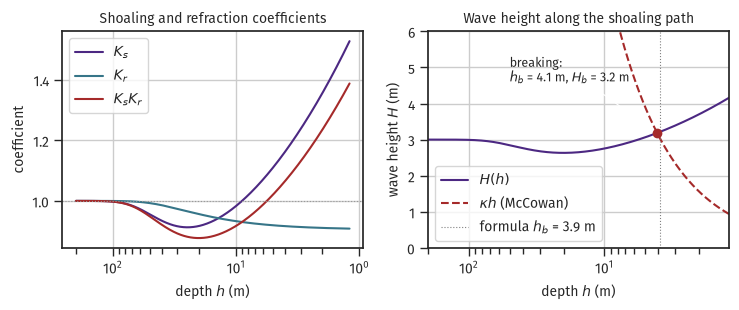

minimum height: H = 2.63 m at h = 20 m


In [3]:
# Shoaling/refraction coefficients and wave height versus depth
h_fine = np.geomspace(1.2, 200.0, 500)
vals = np.array([local_wave(h) for h in h_fine])
Ks_f, Kr_f, H_f = vals[:, 4], vals[:, 5], vals[:, 6]

fig, axes = plt.subplots(1, 2, figsize=(fs.fullwidth, 3.2))

ax = axes[0]
ax.plot(h_fine, Ks_f, label="$K_s$")
ax.plot(h_fine, Kr_f, label="$K_r$")
ax.plot(h_fine, Ks_f * Kr_f, label="$K_s K_r$")
ax.axhline(1.0, color="0.6", linewidth=0.8, linestyle=":")
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_xlabel("depth $h$ (m)")
ax.set_ylabel("coefficient")
ax.set_title("Shoaling and refraction coefficients")
ax.legend()

ax = axes[1]
ax.plot(h_fine, H_f, label="$H(h)$")
ax.plot(h_fine, kappa * h_fine, color=fs.color_list[2], linestyle="--", label=r"$\kappa h$ (McCowan)")
ax.plot(h_b, H_b, "o", color=fs.color_list[2], zorder=5)
ax.annotate(f"breaking:\n$h_b$ = {h_b:.1f} m, $H_b$ = {H_b:.1f} m",
            xy=(h_b, H_b), xytext=(50, 4.6), fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.axvline(h_b_formula, color="0.5", linewidth=0.8, linestyle=":",
           label=f"formula $h_b$ = {h_b_formula:.1f} m")
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_xlim(200, 1.2)
ax.set_ylim(0, 6)
ax.set_xlabel("depth $h$ (m)")
ax.set_ylabel("wave height $H$ (m)")
ax.set_title("Wave height along the shoaling path")
ax.legend(loc="lower left")

fig.tight_layout()
plt.show()

print(f"minimum height: H = {H_f.min():.2f} m at h = {h_fine[np.argmin(H_f)]:.0f} m")

## Problem 2. Refraction: a gauge record and a headland.

### Part A: working back from a gauge

**(a) At the gauge.** $T = 12$ s in $h = 8$ m gives $k = 0.0614$ m$^{-1}$, so

$$
L = 102.3\ \text{m},\quad C = 8.53\ \text{m/s},\quad n = 0.928,\quad C_g = 7.91\ \text{m/s},\quad kh = 0.491 .
$$

This is intermediate depth, close to the shallow end: $C_g$ is within 8% of $C$.

**(b) Back to deep water.** Deep-water values: $L_0 = 224.8$ m, $C_0 = 18.74$ m/s, $C_{g0} = 9.37$ m/s. Run Snell's law backward:

$$
\sin\theta_0 = \frac{C_0}{C}\,\sin\theta = \frac{18.74}{8.53}\,\sin 14^\circ = 0.531
\qquad\Longrightarrow\qquad \theta_0 = 32.1^\circ .
$$

Then $K_s = \sqrt{C_{g0}/C_g} = 1.088$ and $K_r = \sqrt{\cos\theta_0/\cos\theta} = 0.934$, so

$$
H_0 = \frac{H}{K_s K_r} = \frac{1.4}{(1.088)(0.934)} = 1.38\ \text{m}.
$$

Shoaling raises the height by 9% and refraction lowers it by 7%. They almost cancel, and $K_s$ does slightly more. So the gauge reads close to the deep-water height. A gauge reading alone does not tell you $H_0$. You need the direction to undo $K_r$.

**(c) Ray spacing.** With straight contours, two rays that cross a contour $\ell = 100$ m apart stay 100 m apart along every contour. Their perpendicular spacing is $b = \ell\cos\theta$:

$$
b = 100\cos 14^\circ = 97.0\ \text{m}, \qquad b_0 = 100\cos 32.1^\circ = 84.7\ \text{m}.
$$

The rays spread apart as the crests swing toward the shore. With $E = \rho g H^2/8$ ($\rho = 1025$ kg/m$^3$): $E = 2464$ J/m$^2$ at the gauge and $E_0 = 2383$ J/m$^2$ in deep water, so

$$
E\,C_g\,b = (2464)(7.91)(97.0) = 1.89\ \text{MW}, \qquad E_0\,C_{g0}\,b_0 = (2383)(9.37)(84.7) = 1.89\ \text{MW}.
$$

The two are equal. And $\sqrt{b_0/b} = \sqrt{84.7/97.0} = 0.934 = K_r$: the refraction coefficient *is* the ray-spacing ratio.

**(d) The 25 m site.** At $h = 25$ m: $L = 166.0$ m, $C_g = 10.95$ m/s, $\theta = 23.1^\circ$, $K_s = 0.925$, $K_r = 0.960$, so

$$
H = (1.38)(0.925)(0.960) = 1.22\ \text{m}.
$$

That is smaller than at the gauge (1.40 m) *and* smaller than in deep water (1.38 m). This is the dip from Problem 1 again. At 25 m, $C_g$ is *above* $C_{g0}$ (10.95 against 9.37 m/s), so $K_s < 1$. Refraction has also started to spread the rays, so $K_r < 1$. Both lower the height. By 8 m, $C_g$ has fallen back below $C_{g0}$ and shoaling has recovered the loss.

**(e) The 5 s wind sea.** At the gauge, $L = 34.9$ m and $kh = 1.44$, close to deep water. $C = 6.98$ m/s against $C_0 = 7.81$ m/s, so

$$
\sin\theta_0 = \frac{7.81}{6.98}\,\sin 14^\circ = 0.271 \qquad\Longrightarrow\qquad \theta_0 = 15.7^\circ .
$$

The wind sea has turned through 1.7°. The swell has turned through 18.1°. Refraction is driven by the drop in phase speed, $C/C_0$. At 8 m the 12 s swell moves at 46% of its deep-water speed. The 5 s wave is still at 89% of its own. Longer waves feel the bottom in deeper water ($h/L_0$ is smaller for the same $h$). So they start turning farther offshore and have turned more by the time they arrive. Swell crests reach the beach close to parallel with it. Wind-sea crests do not.

### Part B: a headland and a cove

**(f) Heights at 6 m.** $T = 10$ s in $h = 6$ m gives $L = 73.6$ m, $kh = 0.512$, $C_g = 6.79$ m/s, and $K_s = \sqrt{7.81/6.79} = 1.072$. For straight contours at normal incidence $K_r = 1$, so the straight-contour answer is $H = 2.14$ m.

| | $b_0$ (m) | $b$ (m) | $K_r = \sqrt{b_0/b}$ | $H$ (m) |
|---|---:|---:|---:|---:|
| straight contours | 150 | 150 | 1.000 | 2.14 |
| headland tip | 150 | 60 | 1.581 | 3.39 |
| cove | 150 | 260 | 0.760 | 1.63 |

The deep-water wave, the depth, and $K_s$ are the same in all three rows. The headland wave is 58% higher than the straight-coast estimate and the cove wave is 24% lower. Over straight contours $K_r \le 1$. Over curved contours it can exceed 1.

**(g) Energy and breaking.** $E \propto H^2$, so the energy-density ratio is

$$
\frac{E_\text{tip}}{E_\text{cove}} = \left(\frac{3.39}{1.63}\right)^2 = \frac{b_\text{cove}}{b_\text{tip}} = \frac{260}{60} = 4.3 .
$$

Neither is breaking at 6 m: $H/h = 0.57$ at the tip and $0.27$ in the cove, both under 0.78. The headland wave is much closer to the limit, so it will break farther offshore.

Rays converge on the headland and diverge into the cove, so the tip takes more than four times the wave energy per unit area. Headlands erode. Coves get the low-energy waves and collect sand. Pocket beaches between rocky points form this way.


In [4]:
# Problem 2: refraction from a gauge record, and ray convergence over a headland
def wave_at(T, h):
    # Local L, C, Cg, n, kh from the dispersion relation
    omega = 2*np.pi/T
    k = newton_k(omega, h)
    kh = k*h
    C = omega/k
    n = 0.5*(1 + 2*kh/np.sinh(2*kh))
    return 2*np.pi/k, C, n*C, n, kh


# Part A
T2, h_g, H_g, th_g = 12.0, 8.0, 1.4, np.deg2rad(14.0)
L_g, C_g, Cg_g, n_g, kh_g = wave_at(T2, h_g)
C0_2 = g*T2/(2*np.pi)
Cg0_2 = C0_2/2
print(f'(a) L = {L_g:.1f} m, C = {C_g:.2f} m/s, Cg = {Cg_g:.2f} m/s, '
      f'n = {n_g:.3f}, kh = {kh_g:.3f}')

th0_2 = np.arcsin(np.sin(th_g)*C0_2/C_g)
Ks_g = np.sqrt(Cg0_2/Cg_g)
Kr_g = np.sqrt(np.cos(th0_2)/np.cos(th_g))
H0_2 = H_g/(Ks_g*Kr_g)
print(f'(b) L0 = {C0_2*T2:.1f} m, C0 = {C0_2:.2f} m/s, Cg0 = {Cg0_2:.2f} m/s')
print(f'    theta0 = {np.degrees(th0_2):.1f} deg, Ks = {Ks_g:.3f}, Kr = {Kr_g:.3f}, '
      f'H0 = {H0_2:.2f} m')

ell = 100.0
b_g, b_0 = ell*np.cos(th_g), ell*np.cos(th0_2)
E_g, E_0 = rho*g*H_g**2/8, rho*g*H0_2**2/8
print(f'(c) b = {b_g:.1f} m, b0 = {b_0:.1f} m')
print(f'    E Cg b at gauge = {E_g*Cg_g*b_g/1e6:.4f} MW,  '
      f'in deep water = {E_0*Cg0_2*b_0/1e6:.4f} MW')
print(f'    sqrt(b0/b) = {np.sqrt(b_0/b_g):.4f},  Kr = {Kr_g:.4f}')

L25, C25, Cg25, _, _ = wave_at(T2, 25.0)
th25 = np.arcsin(np.sin(th0_2)*C25/C0_2)
Ks25 = np.sqrt(Cg0_2/Cg25)
Kr25 = np.sqrt(np.cos(th0_2)/np.cos(th25))
print(f'(d) h = 25 m: L = {L25:.1f} m, Cg = {Cg25:.2f} m/s, theta = {np.degrees(th25):.1f} deg, '
      f'Ks = {Ks25:.3f}, Kr = {Kr25:.3f}, H = {H0_2*Ks25*Kr25:.2f} m')

L5, C5, _, _, kh5 = wave_at(5.0, h_g)
C0_5 = g*5.0/(2*np.pi)
th0_5 = np.arcsin(np.sin(th_g)*C0_5/C5)
print(f'(e) T = 5 s: L = {L5:.1f} m, kh = {kh5:.2f}, C/C0 = {C5/C0_5:.2f} '
      f'(swell: {C_g/C0_2:.2f}), theta0 = {np.degrees(th0_5):.1f} deg')
print(f'    turned through {np.degrees(th0_5 - th_g):.1f} deg (wind sea) '
      f'vs {np.degrees(th0_2 - th_g):.1f} deg (swell)')

# Part B
TB, H0B, hB = 10.0, 2.0, 6.0
LB, CB, CgB, _, khB = wave_at(TB, hB)
KsB = np.sqrt((g*TB/(4*np.pi))/CgB)
print(f'\n(f) h = 6 m: L = {LB:.1f} m, kh = {khB:.3f}, Cg = {CgB:.2f} m/s, Ks = {KsB:.3f}')
print(f'    {"":18s}{"b0 (m)":>8s}{"b (m)":>8s}{"Kr":>8s}{"H (m)":>8s}{"H/h":>7s}')
H_case = {}
for lab, b0, b in [('straight contours', 150, 150), ('headland tip', 150, 60), ('cove', 150, 260)]:
    Kr = np.sqrt(b0/b)
    H_case[lab] = H0B*KsB*Kr
    print(f'    {lab:18s}{b0:>8.0f}{b:>8.0f}{Kr:>8.3f}{H_case[lab]:>8.2f}{H_case[lab]/hB:>7.2f}')
print(f'(g) E_tip/E_cove = {(H_case["headland tip"]/H_case["cove"])**2:.2f}  '
      f'(= 260/60 = {260/60:.2f})')

(a) L = 102.3 m, C = 8.53 m/s, Cg = 7.91 m/s, n = 0.928, kh = 0.491
(b) L0 = 224.8 m, C0 = 18.74 m/s, Cg0 = 9.37 m/s
    theta0 = 32.1 deg, Ks = 1.088, Kr = 0.934, H0 = 1.38 m
(c) b = 97.0 m, b0 = 84.7 m
    E Cg b at gauge = 1.8913 MW,  in deep water = 1.8913 MW
    sqrt(b0/b) = 0.9343,  Kr = 0.9343
(d) h = 25 m: L = 166.0 m, Cg = 10.95 m/s, theta = 23.1 deg, Ks = 0.925, Kr = 0.960, H = 1.22 m
(e) T = 5 s: L = 34.9 m, kh = 1.44, C/C0 = 0.89 (swell: 0.46), theta0 = 15.7 deg
    turned through 1.7 deg (wind sea) vs 18.1 deg (swell)

(f) h = 6 m: L = 73.6 m, kh = 0.512, Cg = 6.79 m/s, Ks = 1.072
                        b0 (m)   b (m)      Kr   H (m)    H/h
    straight contours      150     150   1.000    2.14   0.36
    headland tip           150      60   1.581    3.39   0.57
    cove                   150     260   0.760    1.63   0.27
(g) E_tip/E_cove = 4.33  (= 260/60 = 4.33)


## Problem 3. Breaking: type, depth, and height.

**(a) Deep-water reference.** $L_0 = gT^2/(2\pi) = 188.9$ m, so the deep-water steepness is

$$
H_0/L_0 = 3.5/188.9 = 0.01853, \qquad \sqrt{H_0/L_0} = 0.1361 .
$$

**(b) Iribarren number and breaker type.**

| slope $m$ | $\xi_0 = m/\sqrt{H_0/L_0}$ | breaker type |
|---|---:|---|
| $1/100$ | 0.073 | spilling ($\xi_0 < 0.5$) |
| $1/30$ | 0.245 | spilling |
| $1/8$ | 0.918 | plunging ($0.5 < \xi_0 < 3.3$) |

For this steepness, the swell breaks by spilling on any slope gentler than about $1/14$. That covers most sandy coasts. A plunging breaker needs a steep slope: cobble, reef, or structure.

**(c) Breaking depth by iteration.** Run the inshore recipe and solve $H(h) = 0.78\,h$:

$$
h_b = 4.97\ \text{m}, \qquad H_b = 3.88\ \text{m}.
$$

At the breakpoint $K_s = 1.156$ and $K_r = 0.959$. So shoaling has raised the height by 16% and refraction has lowered it by 4%. The iterates are printed in the code cell. Six halvings bring the bracket to 0.3 m. About eleven get you to a centimeter.

**(d) Angle at breaking.** Snell's law gives $\theta_b = 9.6^\circ$, down from $25^\circ$ offshore. Refraction has turned the crests through more than fifteen degrees. The remaining ten degrees drives the longshore current inside the surf zone (OE 795/895). Rays never turn all the way to shore-normal: $\sin\theta/C$ is conserved, and $C$ does not reach zero until $h$ does.

**(e) Surf-zone width and amplification.** On a $1/30$ beach the surf zone runs from $h_b = 4.97$ m to the shoreline, a cross-shore distance of $30 h_b = 149$ m. The ratio $H_b/H_0 = 1.11$.

$H_b/H_0 > 1$ is consistent with energy conservation. The conserved quantity is the *flux* $E C_g b$. The energy density $E$ is not conserved. As the wave shoals, $C_g$ falls (from $C_0/2 = 8.6$ m/s offshore to about 6.5 m/s at breaking). So $E$ must rise to keep the product fixed. Since $E \propto H^2$, the height rises too. The wave gains no energy: the same flux moves at a slower speed, so the energy density is larger. Refraction works the other way here. It spreads the rays apart ($K_r < 1$) and lowers the height by a few percent.


(a) L0 = 188.92 m, H0/L0 = 0.01853, sqrt = 0.1361

(b)      slope     xi_0   breaker type
----------------------------------------
     1/100    0.073   spilling
      1/30    0.245   spilling
       1/8    0.918   plunging

(c) bisection on H(h) - 0.78 h:
    iterate 1: h = 10.5000 m,  H - 0.78h = -4.7928 m
    iterate 2: h =  5.7500 m,  H - 0.78h = -0.7154 m
    iterate 3: h =  3.3750 m,  H - 0.78h = +1.5750 m
    iterate 4: h =  4.5625 m,  H - 0.78h = +0.3890 m
    iterate 5: h =  5.1562 m,  H - 0.78h = -0.1707 m
    iterate 6: h =  4.8594 m,  H - 0.78h = +0.1071 m

    h_b = 4.973 m,  H_b = 3.879 m,  H_b/h_b = 0.780
    K_s = 1.156,  K_r = 0.959
(d) theta_b = 9.62 deg  (offshore 25 deg)
(e) surf-zone width on a 1/30 beach = 149 m;  H_b/H_0 = 1.108
    C_g0 = 8.59 m/s -> C_g at breaking = 6.43 m/s (a factor 1.34)


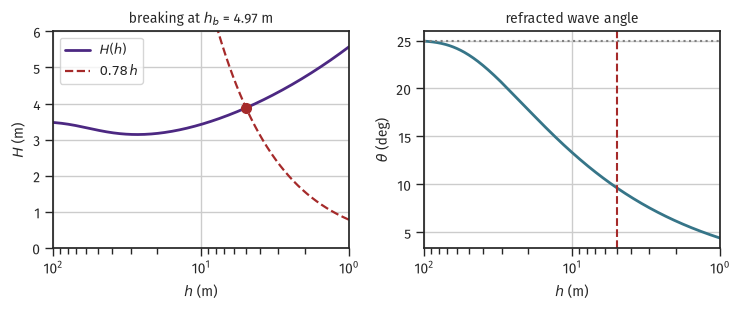

In [5]:
# Problem 3: Iribarren classification and the breaking point
H0_3, T3, theta0_3 = 3.5, 11.0, np.deg2rad(25.0)
omega3 = 2*np.pi/T3
L0_3 = g*T3**2/(2*np.pi)
C0_3 = L0_3/T3
Cg0_3 = C0_3/2
steep = H0_3/L0_3

print(f'(a) L0 = {L0_3:.2f} m, H0/L0 = {steep:.5f}, sqrt = {np.sqrt(steep):.4f}\n')
print(f'(b) {"slope":>10s}{"xi_0":>9s}   breaker type')
print('-'*40)
for m, lab in [(1/100, '1/100'), (1/30, '1/30'), (1/8, '1/8')]:
    xi = m/np.sqrt(steep)
    kind = 'spilling' if xi < 0.5 else ('plunging' if xi < 3.3 else 'surging')
    print(f'{lab:>10s}{xi:>9.3f}   {kind}')


def local3(h):
    k = newton_k(omega3, h)
    kh = k*h
    C = omega3/k
    n = 0.5*(1 + 2*kh/np.sinh(2*kh))
    Cg = n*C
    theta = np.arcsin(np.sin(theta0_3)*C/C0_3)
    Ks = np.sqrt(Cg0_3/Cg)
    Kr = np.sqrt(np.cos(theta0_3)/np.cos(theta))
    return H0_3*Ks*Kr, np.degrees(theta), Ks, Kr, Cg


print('\n(c) bisection on H(h) - 0.78 h:')
lo, hi = 1.0, 20.0
for it in range(6):
    mid = 0.5*(lo + hi)
    f_mid = local3(mid)[0] - 0.78*mid
    print(f'    iterate {it+1}: h = {mid:7.4f} m,  H - 0.78h = {f_mid:+.4f} m')
    if f_mid > 0:
        lo = mid
    else:
        hi = mid
h_b3 = brentq(lambda h: local3(h)[0] - 0.78*h, 1.0, 20.0, xtol=1e-12)
H_b3, th_b3, Ks_b, Kr_b, Cg_b = local3(h_b3)
print(f'\n    h_b = {h_b3:.3f} m,  H_b = {H_b3:.3f} m,  H_b/h_b = {H_b3/h_b3:.3f}')
print(f'    K_s = {Ks_b:.3f},  K_r = {Kr_b:.3f}')
print(f'(d) theta_b = {th_b3:.2f} deg  (offshore {np.degrees(theta0_3):.0f} deg)')
print(f'(e) surf-zone width on a 1/30 beach = {30*h_b3:.0f} m;  '
      f'H_b/H_0 = {H_b3/H0_3:.3f}')
print(f'    C_g0 = {Cg0_3:.2f} m/s -> C_g at breaking = {Cg_b:.2f} m/s '
      f'(a factor {Cg0_3/Cg_b:.2f})')

h_arr = np.geomspace(1.0, 100.0, 400)
H_arr = np.array([local3(h)[0] for h in h_arr])
th_arr = np.array([local3(h)[1] for h in h_arr])

fig, ax = plt.subplots(1, 2, figsize=(fs.fullwidth, 3.2))
ax[0].plot(h_arr, H_arr, lw=2, color=fs.color_list[0], label='$H(h)$')
ax[0].plot(h_arr, 0.78*h_arr, lw=1.6, ls='--', color=fs.color_list[2],
           label=r'$0.78\,h$')
ax[0].plot(h_b3, H_b3, 'o', ms=7, color=fs.color_list[2])
ax[0].set_xscale('log'); ax[0].invert_xaxis()
ax[0].set_xlim(100, 1.0); ax[0].set_ylim(0, 6)
ax[0].set_xlabel('$h$ (m)'); ax[0].set_ylabel('$H$ (m)')
ax[0].set_title(f'breaking at $h_b$ = {h_b3:.2f} m')
ax[0].legend(fontsize=9)

ax[1].plot(h_arr, th_arr, lw=2, color=fs.color_list[1])
ax[1].axhline(np.degrees(theta0_3), ls=':', color='0.5')
ax[1].axvline(h_b3, ls='--', color=fs.color_list[2])
ax[1].set_xscale('log'); ax[1].invert_xaxis()
ax[1].set_xlim(100, 1.0)
ax[1].set_xlabel('$h$ (m)'); ax[1].set_ylabel(r'$\theta$ (deg)')
ax[1].set_title('refracted wave angle')
fig.tight_layout()
plt.show()

## Problem 4 (Graduate students only). Seiches: a basin and a harbor.

**(a) Closed basin.** $\ell = 3200$ m, $h = 6$ m, so $\sqrt{gh} = 7.672$ m/s and $T_n = 2\ell/(n\sqrt{gh})$:

| $n$ | $T_n$ (s) | $T_n$ (min) |
|---:|---:|---:|
| 1 | 834 | 13.90 |
| 2 | 417 | 6.95 |
| 3 | 278 | 4.63 |

The $n = 1$ surface shape is $\eta \propto \cos(\pi x/\ell)$. There are **antinodes at both ends**, where the surface displacement is largest and the current is zero. There is a **node at the center**, where the surface never moves and the current is largest. Surface displacement and current are in quadrature in space and in time, as for any standing wave. A gauge at the center of a seiching basin sees nothing.

**(b) Opened at one end.** A node at the open end and an antinode at the closed end makes the fundamental a quarter wave, $T_n = 4\ell/[(2n-1)\sqrt{gh}]$:

| $n$ | closed–closed (min) | open–closed (min) |
|---:|---:|---:|
| 1 | 13.90 | 27.81 |
| 2 | 6.95 | 9.27 |
| 3 | 4.63 | 5.56 |

Every period lengthens. The fundamental doubles: the basin now holds a quarter wave instead of a half wave. The higher modes lengthen by less ($\times 1.33$, $\times 1.20$), since the ratio $2n/(2n-1) \to 1$.

**(c) Helmholtz mode.** $A_c = 45\times5 = 225$ m$^2$, so

$$
T_H = 2\pi\sqrt{\frac{(2.4\times10^{5})(120)}{9.81\times225}} = 718\ \text{s} = 11.96\ \text{min}.
$$

The quarter-wave estimate using $\sqrt{A_b} = 490$ m as the basin length gives $4\times490/\sqrt{9.81\times5} = 280$ s $= 4.66$ min. The Helmholtz mode is **2.6 times longer** than the basin's own quarter-wave mode.

This ordering is typical for a harbor with a constricted entrance, so the two modes are treated separately. The quarter-wave mode is set by how long a wave takes to cross the basin. The Helmholtz mode is set by how long it takes to push the plug of water in the entrance channel back and forth. A narrow entrance makes that slow. The narrower the mouth, the longer $T_H$.

**(d) Infragravity forcing at 4 minutes.** The mode closest to 240 s is the closed-basin $n = 3$ at 278 s. The open-mouth $n = 3$ at 334 s is not far off. The harbor's quarter-wave mode at 280 s is close too. So the third mode is the one at risk, and the one to detune.

To move it, change $\ell/\sqrt{h}$. Dredging raises $\sqrt{h}$ and shortens every period. Shortening the basin does the same. Dredging from 6 m to 9 m would move the $n = 3$ mode from 278 s to 227 s. That is inside the 240 s band, so it makes things worse. Deepening further, to 12 m, brings it to 197 s, past the band.

Deepening affects everything else too. It moves *all* the modes, and one of them may land on some other forcing (the $n = 2$ mode would move from 417 s to 295 s). It also enlarges the tidal prism and the throat and changes the flushing time. The dredged sand has to go somewhere. A wider entrance shortens $T_H$, but also lets more short-wave energy in. Detuning a harbor is a trade-off.


basin: ell = 3200 m, h = 6 m, sqrt(gh) = 7.672 m/s

  n   closed T (s)    (min)   open T (s)    (min)   ratio
---------------------------------------------------------
  1          834.2    13.90       1668.4    27.81    2.00
  2          417.1     6.95        556.1     9.27    1.33
  3          278.1     4.63        333.7     5.56    1.20

harbor: A_b = 2.40e+05 m^2, channel 120 x 45 x 5 m, A_c = 225 m^2
  Helmholtz  T_H = 717.7 s = 11.96 min
  quarter wave over sqrt(A_b) = 490 m: T = 279.8 s = 4.66 min
  ratio T_H / T_quarter = 2.57

(d) infragravity forcing at 240 s. distances from the modes:
    closed n=3              278.1 s   (+16% from 240 s)
    open n=3                333.7 s   (+39% from 240 s)
    harbor quarter wave     279.8 s   (+17% from 240 s)
    closed n=2              417.1 s   (+74% from 240 s)

    dredging the basin, n = 3 mode:
      h =  6.0 m  ->  T_3 =  278.1 s,   T_2 =  417.1 s
      h =  9.0 m  ->  T_3 =  227.0 s,   T_2 =  340.6 s
      h = 12.0 m  ->  T_3 

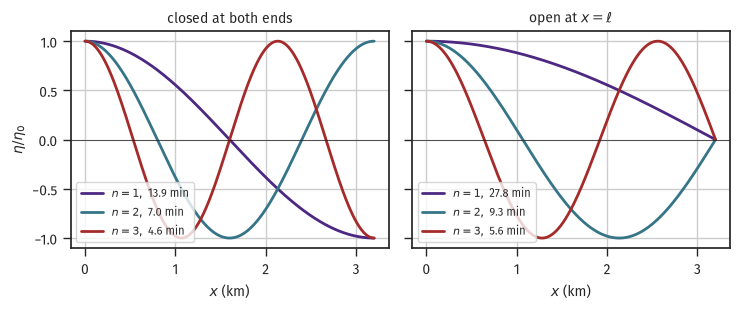

In [6]:
# Problem 4: Merian modes, quarter-wave case, Helmholtz mode
ell4, h4 = 3200.0, 6.0
c4 = np.sqrt(g*h4)
n = np.arange(1, 4)
T_closed = 2*ell4/(n*c4)
T_open = 4*ell4/((2*n - 1)*c4)

print(f'basin: ell = {ell4:.0f} m, h = {h4:.0f} m, sqrt(gh) = {c4:.3f} m/s\n')
print(f'{"n":>3s}{"closed T (s)":>15s}{"(min)":>9s}{"open T (s)":>13s}{"(min)":>9s}'
      f'{"ratio":>8s}')
print('-'*57)
for i, ni in enumerate(n):
    print(f'{ni:>3d}{T_closed[i]:>15.1f}{T_closed[i]/60:>9.2f}'
          f'{T_open[i]:>13.1f}{T_open[i]/60:>9.2f}{T_open[i]/T_closed[i]:>8.2f}')

A_b4, ell_c, b_c, h_c = 2.4e5, 120.0, 45.0, 5.0
A_c4 = b_c*h_c
T_H = 2*np.pi*np.sqrt(A_b4*ell_c/(g*A_c4))
T_qw = 4*np.sqrt(A_b4)/np.sqrt(g*h_c)
print(f'\nharbor: A_b = {A_b4:.2e} m^2, channel {ell_c:.0f} x {b_c:.0f} x {h_c:.0f} m, '
      f'A_c = {A_c4:.0f} m^2')
print(f'  Helmholtz  T_H = {T_H:.1f} s = {T_H/60:.2f} min')
print(f'  quarter wave over sqrt(A_b) = {np.sqrt(A_b4):.0f} m: '
      f'T = {T_qw:.1f} s = {T_qw/60:.2f} min')
print(f'  ratio T_H / T_quarter = {T_H/T_qw:.2f}')

print(f'\n(d) infragravity forcing at 240 s. distances from the modes:')
for lab, T in [('closed n=3', T_closed[2]), ('open n=3', T_open[2]),
               ('harbor quarter wave', T_qw), ('closed n=2', T_closed[1])]:
    print(f'    {lab:<22s}{T:7.1f} s   ({T/240 - 1:+.0%} from 240 s)')
print('\n    dredging the basin, n = 3 mode:')
for h_new in (6.0, 9.0, 12.0):
    print(f'      h = {h_new:4.1f} m  ->  T_3 = {2*ell4/(3*np.sqrt(g*h_new)):6.1f} s,'
          f'   T_2 = {2*ell4/(2*np.sqrt(g*h_new)):6.1f} s')

x = np.linspace(0, ell4, 500)
fig, ax = plt.subplots(1, 2, figsize=(fs.fullwidth, 3.2), sharey=True)
for i, ni in enumerate(n):
    ax[0].plot(x/1000, np.cos(ni*np.pi*x/ell4), lw=2, color=fs.color_list[i],
               label=f'$n = {ni}$,  {T_closed[i]/60:.1f} min')
    ax[1].plot(x/1000, np.cos((2*ni - 1)*np.pi*x/(2*ell4)), lw=2,
               color=fs.color_list[i], label=f'$n = {ni}$,  {T_open[i]/60:.1f} min')
ax[0].set_title('closed at both ends')
ax[1].set_title(r'open at $x = \ell$')
for a in ax:
    a.axhline(0, color='k', lw=0.5)
    a.set_xlabel('$x$ (km)')
    a.legend(fontsize=8, loc='lower left')
ax[0].set_ylabel(r'$\eta/\eta_0$')
fig.tight_layout()
plt.show()

## Checks to remember

- Shoaling first *lowers* the wave height and then raises it, since $C_g$ peaks at intermediate depth before dropping. Obliquely incident swell shows this dip, then rise. So "shoaling always makes waves bigger" is wrong offshore.
- A nearshore gauge reading is not the deep-water height. $K_s$ and $K_r$ can nearly cancel, and undoing them needs the direction as well as $H$. Long-period swell feels the bottom farther offshore, so it turns far more than wind sea at the same depth.
- $K_r = \sqrt{b_0/b}$ is the ray-spacing ratio. Over straight contours rays only spread, so $K_r \le 1$. Over a headland they converge and $K_r$ can exceed 1. A factor of four in ray spacing is a factor of four in energy density.
- The breaking calculation is a root-finding problem. $H(h)$ comes from the inshore recipe and $0.78h$ comes from McCowan. They cross at the breakpoint. The closed-form $h_b$ is the shallow-water asymptote of the same statement, good to about 5%.
- Basin modes scale as $\ell/\sqrt{h}$ and harbor Helmholtz modes as $\sqrt{A_b\ell_c/A_c}$ (no basin depth in the second). A narrow entrance makes the Helmholtz period long. Detuning a harbor by geometry alone always moves other modes too.
